# Bridge Design Optimization Demo
### Multi-Objective Decision Optimization with Multiple Decision Makers

# The Bridge Design Challenge

A coastal town needs a new bridge across its harbor. Two key decision makers have different priorities:

**The Town Council (Decision maker 1)** is concerned about the budget. They want to keep costs reasonable (ideally below $80), but they don't care on how long it takes to build.

**The Harbor Authority (Decision maker 2)** needs the bridge to accommodate boat traffic. They're less concerned about cost but insist the construction time must be under 60 days to minimize disruption to maritime commerce.

The design configuration (bridge span and air draft) affect both cost and construction time in complex ways.

<img src="../docs/assets/bridge_example.png" alt="Bridge Example" width="800"/>

### How Preferendus Helps

The Preferendus approach allows us to:
1. Explicitly model each decision maker's preferences as mathematical functions
2. Balance competing objectives (cost vs. time)
3. Find an optimal design that maximizes overall satisfaction
4. Visualize how well the solution meets each decision maker's needs

Instead of endless negotiations, this mathematical approach finds the design that offers the best compromise for all parties involved.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from igs_ga.optimization.modo import Preferendus

# Decision makers Preference Functions
### Each decicision maker has different preferences for cost and time
- **Decision maker 1**: Prefers lower costs (ideal: < $80), accepts any time reduction

- **Decision maker 2**: accepts any costs, but time must be < 60 days

In [2]:
def p_1_c(c):
    return max(0, min(100, (225 - c) / (225 - 80) * 100))

def p_1_t(t):
    return max(0, min(100, (120 - 0) / 120 * 100))

def p_2_c(c):
    return max(0, min(100, (130 - 0) / (130 - 10) * 100))

def p_2_t(t):
    return max(0, min(100, (120 - t) / (120 - 60) * 100))

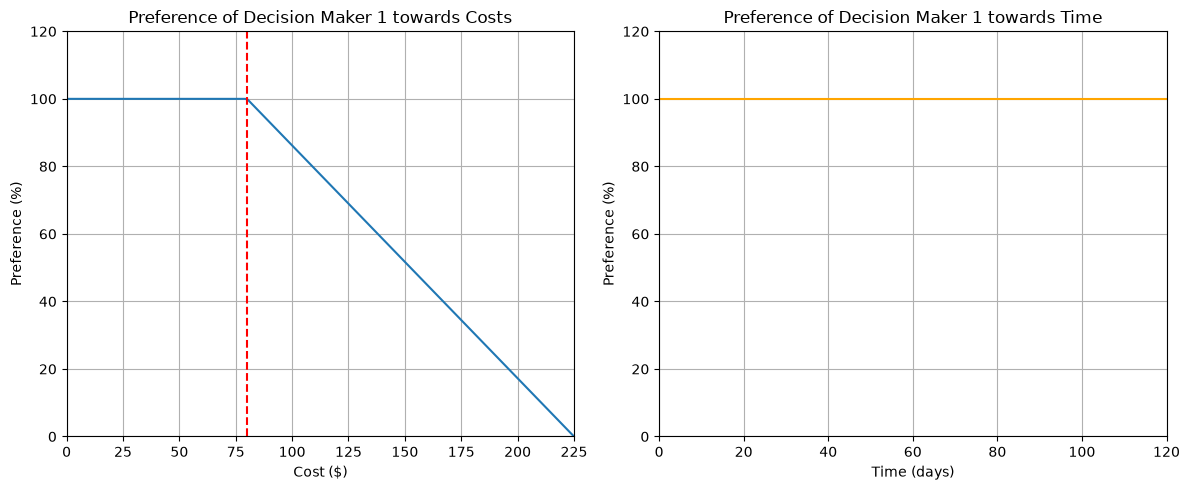

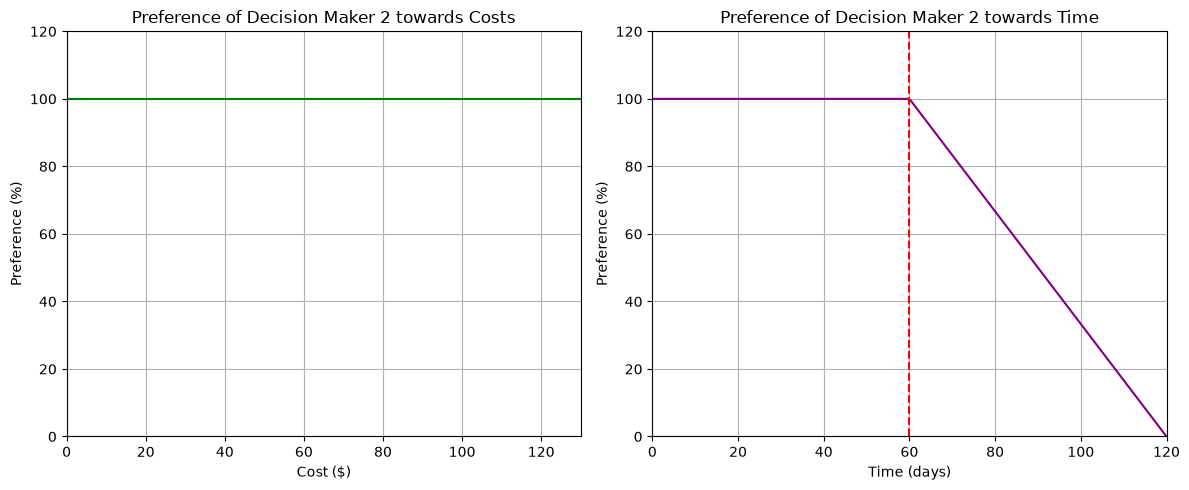

In [3]:
cost_range = np.linspace(0,225,200)
time_range = np.linspace(0,120,200)

# # Preference Visualizations
# ### Comparing how stakeholders value cost vs. time

# Create a figure for Stakeholder 1 with two subplots
plt.figure(figsize=(12, 5))

# Decision maker 1 - Cost preference
plt.subplot(1, 2, 1)
plt.plot(cost_range, [p_1_c(c) for c in cost_range])
plt.xlabel('Cost ($)')
plt.ylabel('Preference (%)')
plt.title('Preference of Decision Maker 1 towards Costs')
plt.xlim(0, 225)
plt.ylim(0, 120)
plt.axvline(80, color="red", linestyle="--")
plt.grid(True)

# Decision maker 1 - Time preference
plt.subplot(1, 2, 2)
plt.plot(time_range, [p_1_t(t) for t in time_range], color='orange')
plt.xlabel('Time (days)')
plt.ylabel('Preference (%)')
plt.title('Preference of Decision Maker 1 towards Time')
plt.xlim(0, 120)
plt.ylim(0, 120)
plt.grid(True)

plt.tight_layout()
plt.show()

# Create a figure for Stakeholder 2 with two subplots
plt.figure(figsize=(12, 5))

# Decision maker 2 - Cost preference
plt.subplot(1, 2, 1)
plt.plot(cost_range, [p_2_c(c) for c in cost_range], color='green')
plt.xlabel('Cost ($)')
plt.ylabel('Preference (%)')
plt.title('Preference of Decision Maker 2 towards Costs')
plt.xlim(0, 130)
plt.ylim(0, 120)
# plt.axvline(10, color="red", linestyle="--")
plt.grid(True)

# Decision maker 2 - Time preference
plt.subplot(1, 2, 2)
plt.plot(time_range, [p_2_t(t) for t in time_range], color='purple')
plt.xlabel('Time (days)')
plt.ylabel('Preference (%)')
plt.title('Preference of Decision Maker 2 towards Time')
plt.xlim(0, 120)
plt.ylim(0, 120)
plt.axvline(60, color="red", linestyle="--")
plt.grid(True)

plt.tight_layout()
plt.show()

# Setting Up the Optimization Problem
### Step 1: Define the preferences and objectives

In [4]:
stakeholder_preferences = {
    1: {
        "cost": p_1_c,
        "time": p_1_t,
    },
    2: {
        "cost": p_2_c,
        "time": p_2_t,
    },
}

### Step 2: Configure objective weights
- Stakeholder 1 cares only about cost
- Stakeholder 2 cares only about time

In [5]:
objective_weights = {
    1: {"cost": 1, "time": 0},
    2: {"cost": 0, "time": 1},
}

### Step 3: Configure optimization algorithm settings
- Genetic algorithm parameters for finding optimal solution

In [6]:
optimization_options = {
    'population_size': 100,
    'generations': 15,
    'mutation_rate': 0.80,
    'hall_of_fame_size':100,
}

# Bridge Design Simulation Model
### Decision variables: Bridge span and air draft
- x[0]: Bridge span (meters)
- x[1]: Air draft (meters)

In [7]:
k1 = 3   # costs per material
k2 = 4   # material used per metre bridge span
k3 = 7   # material used per metre air draft
k4 = 1.2   # relation between waiting time and traffic flow
k5 = 1.7   # traffic flow per metre bridge span
k6 = 1.9   # traffic flow per metre air draft
WT0 = 100

# # Multi-Objective Decision Optimization (Preferendus)
# ### Setting up the optimization framework
# - Equal weights (0.5, 0.5) for both stakeholders
# - Decision variables: Bridge span (1-5m) and air draft (3-8m)

@Preferendus(
     preference_functions=stakeholder_preferences,
     stakeholder_weights=[0.5, 0.5],
     variable_types=[float, float],
     value_range=[(1.0, 5.0), (3.0, 8.0)],
     objective_weights=objective_weights,
     optimization_options=optimization_options,
)
def bridge_project(x):
    # Simulation logic here
    F1 = k2 * x[0] + k3 * x[1]
    F2 = k5 * x[0] + k6 * x[1]
    cost = k1*F1
    time = -1 * k4 * F2 + WT0
    return None, None, cost, time

# Running the Optimization
### Finding the optimal bridge design that balances stakeholder preferences

In [8]:
result = bridge_project([1,3])  # Initial guess or can be omitted
print(f"Optimal variables: {result['x_opt']}, Utility: {result['utility']}")

Created initial population
Evaluating initial population...
Initial population evaluated
Starting evolutionary algorithm...
gen	nevals
0  	100   


Generation 1: Difference in relative utility score between best and worst individual is 33.37% of the Hall of Fame.
1  	200   


Generation 2: Difference in relative utility score between best and worst individual is 17.90% of the Hall of Fame.
2  	200   


Generation 3: Difference in relative utility score between best and worst individual is 9.48% of the Hall of Fame.
3  	200   


Generation 4: Difference in relative utility score between best and worst individual is 5.91% of the Hall of Fame.
4  	200   


Generation 5: Difference in relative utility score between best and worst individual is 3.54% of the Hall of Fame.
5  	200   


... (6 outputs left out)

Generation 12: Difference in relative utility score between best and worst individual is 1.94% of the Hall of Fame.
12 	200   


Generation 13: Difference in relative utility score between best and worst individual is 1.70% of the Hall of Fame.
13 	200   


Generation 14: Difference in relative utility score between best and worst individual is 1.55% of the Hall of Fame.
14 	200   


Generation 15: Difference in relative utility score between best and worst individual is 1.42% of the Hall of Fame.
15 	200   
Evolution completed
Final objective values: {'cost': 125.22202883026183, 'time': 82.73137766402681}
Final preference scores: [68.81239391016425, 62.114370559955326]
Final weights: [0.5, 0.5]
Final utility (weighted sum): 65.46338223505978
Total solutions evaluated: 10700
Optimal variables: [4.982871015661511, 3.1155988877297003], Utility: 65.46338223505978


In [9]:
# # Verification and Results Analysis
# ### Understanding the optimal solution and stakeholder satisfaction

# Let's manually calculate the utility for the optimal solution to verify
opt_x = result['x_opt']
# Calculate objective values
F1_opt = k2 * opt_x[0] + k3 * opt_x[1]
F2_opt = k5 * opt_x[0] + k6 * opt_x[1]
cost_opt = k1*F1_opt
time_opt = -1 * k4 * F2_opt + WT0

# Calculate preference scores
pref_s1_cost = stakeholder_preferences[1]['cost'](cost_opt)
pref_s2_time = stakeholder_preferences[2]['time'](time_opt)

# Since objective weights are [1,0] for stakeholder 1 and [0,1] for stakeholder 2
# And stakeholder weights are [0.5, 0.5]
# The normalized weights for cost and time should be [0.5, 0.5]
final_utility = 0.5 * pref_s1_cost + 0.5 * pref_s2_time

print("Manual calculation:")
print(f"cost={F1_opt}, time={F2_opt}")
print(f"pref_s1_cost={pref_s1_cost}, pref_s2_time={pref_s2_time}")
print(f"Final utility = 0.5 * {pref_s1_cost} + 0.5 * {pref_s2_time} = {final_utility}")

Manual calculation:
cost=41.740676276753945, time=14.390518613310999
pref_s1_cost=68.81239391016425, pref_s2_time=62.114370559955326
Final utility = 0.5 * 68.81239391016425 + 0.5 * 62.114370559955326 = 65.46338223505978


In [10]:
print(cost_opt)
print(time_opt)

125.22202883026183
82.73137766402681


In [11]:
# Verify preference scores for final solution
print("Stakeholder 1 cost preference:", stakeholder_preferences[1]['cost'](cost_opt))
print("Stakeholder 1 time preference:", stakeholder_preferences[1]['time'](time_opt))
print("Stakeholder 2 cost preference:", stakeholder_preferences[2]['cost'](cost_opt))
print("Stakeholder 2 time preference:", stakeholder_preferences[2]['time'](time_opt))


Stakeholder 1 cost preference: 68.81239391016425
Stakeholder 1 time preference: 100
Stakeholder 2 cost preference: 100
Stakeholder 2 time preference: 62.114370559955326


# Mapping Results on Preference Functions
### Visualizing where the optimal solution falls on each stakeholder's preference curves

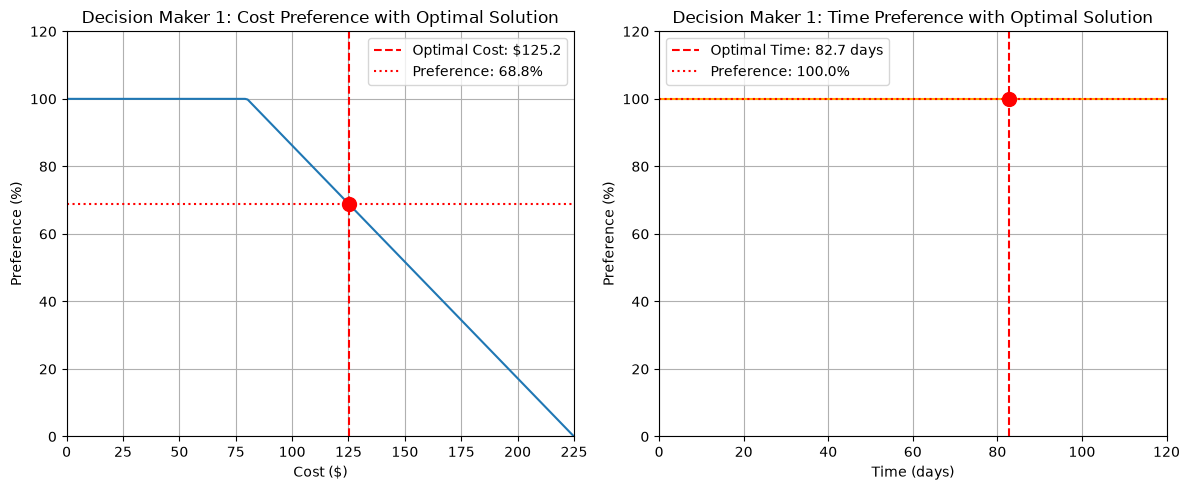

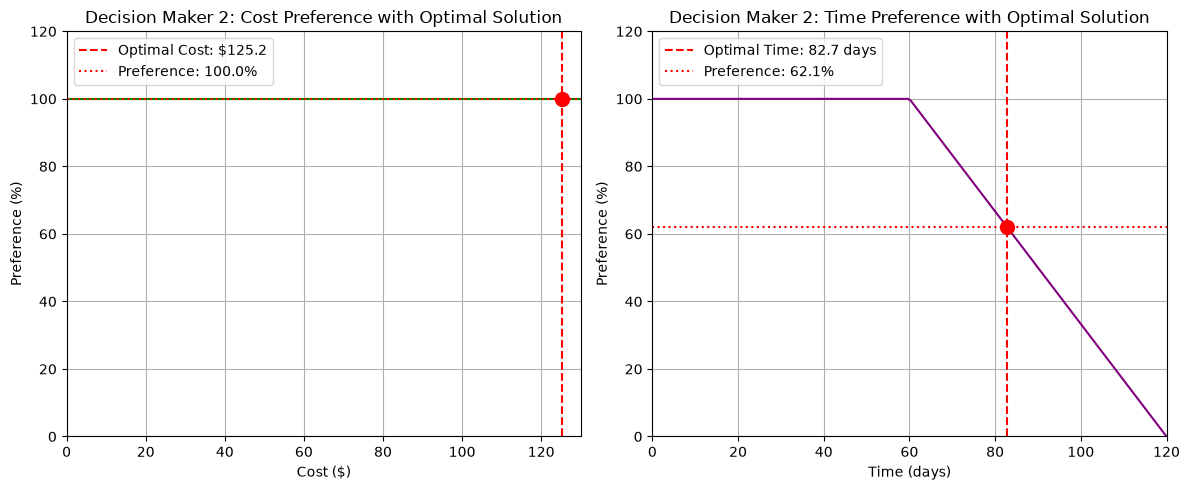

In [12]:
# Create a figure to map results for Stakeholder 1
plt.figure(figsize=(12, 5))

# Stakeholder 1 - Cost preference
plt.subplot(1, 2, 1)
plt.plot(cost_range, [p_1_c(c) for c in cost_range])
plt.axvline(cost_opt, color="red", linestyle="--", label=f"Optimal Cost: ${cost_opt:.1f}")
plt.axhline(stakeholder_preferences[1]['cost'](cost_opt), color="red", linestyle=":",
          label=f"Preference: {stakeholder_preferences[1]['cost'](cost_opt):.1f}%")
plt.scatter(cost_opt, stakeholder_preferences[1]['cost'](cost_opt), color='red', s=100, zorder=5)
plt.xlabel('Cost ($)')
plt.ylabel('Preference (%)')
plt.title('Decision Maker 1: Cost Preference with Optimal Solution')
plt.xlim(0, 225)
plt.ylim(0, 120)
plt.grid(True)
plt.legend()

# Stakeholder 1 - Time preference
plt.subplot(1, 2, 2)
plt.plot(time_range, [p_1_t(t) for t in time_range], color='orange')
plt.axvline(time_opt, color="red", linestyle="--", label=f"Optimal Time: {time_opt:.1f} days")
plt.axhline(stakeholder_preferences[1]['time'](time_opt), color="red", linestyle=":",
          label=f"Preference: {stakeholder_preferences[1]['time'](time_opt):.1f}%")
plt.scatter(time_opt, stakeholder_preferences[1]['time'](time_opt), color='red', s=100, zorder=5)
plt.xlabel('Time (days)')
plt.ylabel('Preference (%)')
plt.title('Decision Maker 1: Time Preference with Optimal Solution')
plt.xlim(0, 120)
plt.ylim(0, 120)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Create a figure to map results for Stakeholder 2
plt.figure(figsize=(12, 5))

# Stakeholder 2 - Cost preference
plt.subplot(1, 2, 1)
plt.plot(cost_range, [p_2_c(c) for c in cost_range], color='green')
plt.axvline(cost_opt, color="red", linestyle="--", label=f"Optimal Cost: ${cost_opt:.1f}")
plt.axhline(stakeholder_preferences[2]['cost'](cost_opt), color="red", linestyle=":",
          label=f"Preference: {stakeholder_preferences[2]['cost'](cost_opt):.1f}%")
plt.scatter(cost_opt, stakeholder_preferences[2]['cost'](cost_opt), color='red', s=100, zorder=5)
plt.xlabel('Cost ($)')
plt.ylabel('Preference (%)')
plt.title('Decision Maker 2: Cost Preference with Optimal Solution')
plt.xlim(0, 130)
plt.ylim(0, 120)
plt.grid(True)
plt.legend()

# Stakeholder 2 - Time preference
plt.subplot(1, 2, 2)
plt.plot(time_range, [p_2_t(t) for t in time_range], color='purple')
plt.axvline(time_opt, color="red", linestyle="--", label=f"Optimal Time: {time_opt:.1f} days")
plt.axhline(stakeholder_preferences[2]['time'](time_opt), color="red", linestyle=":",
          label=f"Preference: {stakeholder_preferences[2]['time'](time_opt):.1f}%")
plt.scatter(time_opt, stakeholder_preferences[2]['time'](time_opt), color='red', s=100, zorder=5)
plt.xlabel('Time (days)')
plt.ylabel('Preference (%)')
plt.title('Decision Maker 2: Time Preference with Optimal Solution')
plt.xlim(0, 120)
plt.ylim(0, 120)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()
